# Tahap 3: Feature Engineering, Scaling, Korelasi, Seleksi Fitur, dan Indeks Risiko
**Project Akhir Data Wrangling: Indeks Risiko Bencana Terpadu Kab/Kota di Jawa**

Input: `tahap2_clean.csv` dari tahap 2 (dicari otomatis di semua folder kerja).
Output: `data/interim/tahap3_features.csv` (fitur, versi ter-scaling, dan skor indeks per kab/kota).

Alur: feature engineering (termasuk reshaping), transformasi dan scaling, korelasi (heatmap), seleksi fitur, penyusunan indeks `Risiko = Bahaya x Paparan / Kapasitas`, lalu validasi terhadap skor IRBI resmi BNPB.

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import MinMaxScaler, StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

hit = sorted(Path(".").rglob("clean*.csv"))
assert hit, "tahap2_clean.csv tidak ditemukan: jalankan tahap 2 sampai akhir atau upload filenya"
IN = hit[0]
OUT = Path("data/interim"); OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(IN)
df["CC_2"] = df["CC_2"].astype(str)
print("file:", IN, "| bentuk:", df.shape)

file: clean.csv | bentuk: (100, 41)


## 1. Feature engineering
Dua hal yang dilakukan: **reshaping** (wide ke long untuk melihat tren karhutla per tahun) dan **membuat fitur baru** per komponen risiko.

In [12]:
kol_th = [f"karhutla_{y}" for y in range(2018, 2026)]
panjang = df.melt(id_vars=["CC_2", "NAME_1", "NAME_2"], value_vars=kol_th, var_name="tahun", value_name="luas_ha")
panjang["tahun"] = panjang["tahun"].str[-4:].astype(int)

print("Total luas karhutla per tahun (ha), 3 provinsi:")
print(panjang.groupby("tahun")["luas_ha"].sum().round(0).to_string())
print("\nMedian karhutla total per provinsi:")
print(df.groupby("NAME_1")["karhutla_total_2018_2025"].median().round(0).to_string())

Total luas karhutla per tahun (ha), 3 provinsi:
tahun
2018    13286.0
2019    37988.0
2020    29006.0
2021    17358.0
2022     4492.0
2023    70989.0
2024    29233.0
2025    13650.0

Median karhutla total per provinsi:
NAME_1
Jawa Barat       32.0
Jawa Tengah     520.0
Jawa Timur     2037.0


In [13]:
fe = df.copy()

fe["log_energi_100"] = np.log10(fe["energi_rel_100km"])
fe["log_n_gempa_100"] = np.log1p(fe["n_gempa_100km"])
fe["dangkal_100"] = -fe["kedalaman_rata_100km"]

th = np.arange(2018, 2026)
v = fe[kol_th].values
fe["karhutla_tren"] = ((th - th.mean()) * (v - v.mean(axis=1, keepdims=True))).sum(axis=1) / ((th - th.mean()) ** 2).sum()
fe["karhutla_tahun_aktif"] = (v > 0).sum(axis=1)
fe["log_karhutla_total"] = np.log1p(fe["karhutla_total_2018_2025"])

fe["log_pop"] = np.log10(fe["pop_total"])
fe["prop_rentan"] = fe["prop_anak_0_14"] + fe["prop_lansia_65"]

fe["rs_per_100k"] = fe["n_rs"] / fe["pop_total"] * 100_000
fe["puskesmas_per_100k"] = fe["n_puskesmas"] / fe["pop_total"] * 100_000

KANDIDAT = ["n_gempa_50km", "n_gempa_100km", "n_gempa_150km", "log_n_gempa_100", "log_energi_100", "mag_max_100km", "dangkal_100",
            "log_karhutla_total", "karhutla_tren", "karhutla_tahun_aktif", "gfw_loss_rasio",
            "log_pop", "prop_anak_0_14", "prop_lansia_65", "prop_rentan",
            "faskes_per_100k", "rs_per_100k", "puskesmas_per_100k"]
fe[KANDIDAT].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
n_gempa_50km,100.0,9.22,9.43,0.00,3.75,6.00,11.25,58.00
n_gempa_100km,100.0,44.67,39.26,8.00,17.00,29.00,59.50,181.00
n_gempa_150km,100.0,115.10,79.07,34.00,59.00,86.00,138.75,342.00
log_n_gempa_100,100.0,3.51,0.78,2.20,2.89,3.40,4.10,5.20
log_energi_100,100.0,2.78,0.80,1.33,2.10,2.86,3.34,4.62
mag_max_100km,100.0,5.60,0.65,4.40,5.05,5.75,6.00,7.00
dangkal_100,100.0,-127.42,52.27,-369.74,-138.17,-121.46,-101.63,-33.77
log_karhutla_total,100.0,4.79,3.51,0.00,0.00,6.25,7.73,10.55
karhutla_tren,100.0,8.55,62.53,-200.78,-0.99,0.00,11.22,301.82
karhutla_tahun_aktif,100.0,3.43,2.90,0.00,0.00,3.50,6.00,8.00


## 2. Transformasi dan scaling
Fitur yang masih sangat miring ke kanan (skewness > 1) dan tidak bernilai negatif ditransformasi `log1p` dulu. Setelah itu dua jenis scaling:
- **Min-Max (0 sampai 1)** untuk **indeks**, karena skornya mudah dibaca dan bisa dirata-ratakan antar komponen.
- **Z-score** untuk **clustering** (tahap 4), karena jarak antar titik dipengaruhi simpangan baku.

In [14]:
skew_awal = fe[KANDIDAT].skew()
T = fe[KANDIDAT].copy()
dilog = [c for c in KANDIDAT if skew_awal[c] > 1 and T[c].min() >= 0]
T[dilog] = np.log1p(T[dilog])
print("fitur yang di-log1p:", dilog)
print(pd.DataFrame({"skew_sebelum": skew_awal, "skew_sesudah": T.skew()}).round(2).loc[dilog])

mm = pd.DataFrame(MinMaxScaler().fit_transform(T), columns=[f"{c}_mm" for c in T.columns], index=fe.index)
zs = pd.DataFrame(StandardScaler().fit_transform(T), columns=[f"{c}_z" for c in T.columns], index=fe.index)
print("\nrentang Min-Max:", mm.min().min(), "-", mm.max().max(), "| rata-rata Z:", round(zs.mean().abs().max(), 6))

fitur yang di-log1p: ['n_gempa_50km', 'n_gempa_100km', 'n_gempa_150km', 'gfw_loss_rasio', 'faskes_per_100k', 'rs_per_100k', 'puskesmas_per_100k']
                    skew_sebelum  skew_sesudah
n_gempa_50km                2.52          0.16
n_gempa_100km               1.59          0.33
n_gempa_150km               1.34          0.47
gfw_loss_rasio              2.64          2.54
faskes_per_100k             2.14          1.19
rs_per_100k                 2.33          1.18
puskesmas_per_100k          1.61          0.64

rentang Min-Max: 0.0 - 1.0000000000000004 | rata-rata Z: 0.0


## 3. Analisis korelasi (Spearman) dan heatmap
Dipakai **Spearman** (berbasis peringkat), bukan Pearson, karena data miring dan outlier sengaja dipertahankan di tahap 2. Pearson sangat sensitif terhadap outlier.

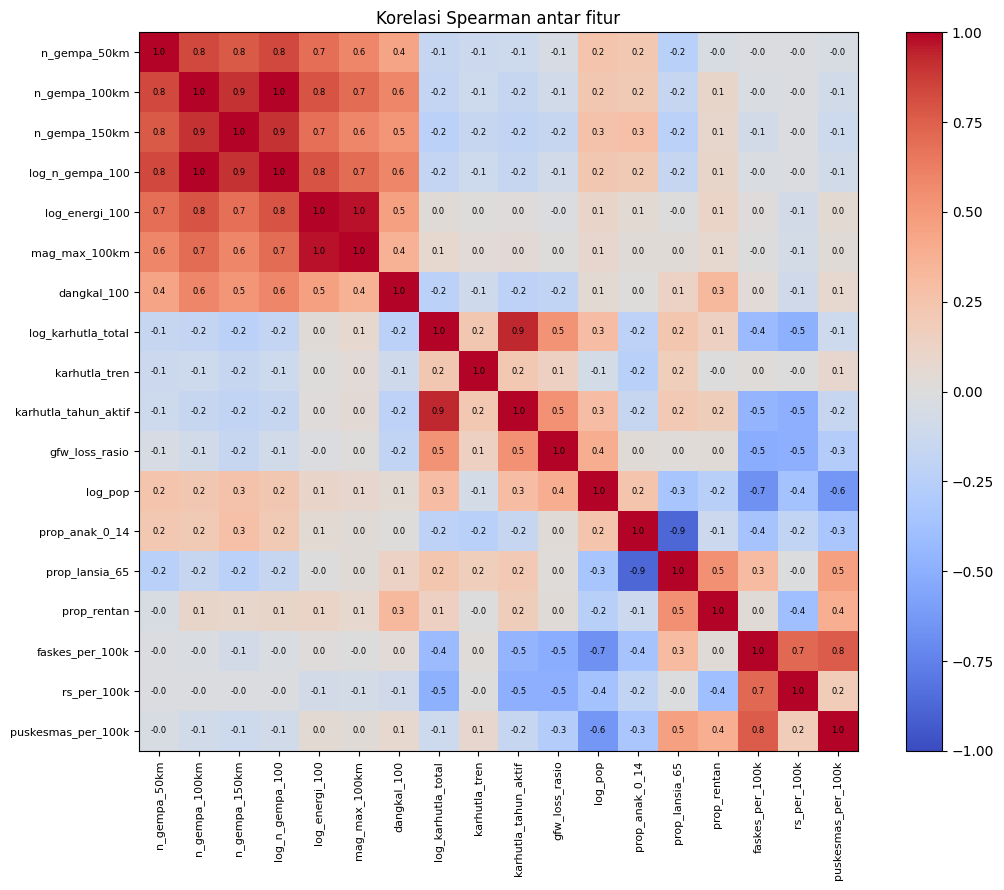

,fitur_a,fitur_b,rho,abs_rho
18,n_gempa_100km,log_n_gempa_100,1.00,1.00
62,log_energi_100,mag_max_100km,0.97,0.97
99,log_karhutla_total,karhutla_tahun_aktif,0.94,0.94
17,n_gempa_100km,n_gempa_150km,0.90,0.90
33,n_gempa_150km,log_n_gempa_100,0.90,0.90
138,prop_anak_0_14,prop_lansia_65,-0.87,0.87
0,n_gempa_50km,n_gempa_100km,0.83,0.83
2,n_gempa_50km,log_n_gempa_100,0.83,0.83
19,n_gempa_100km,log_energi_100,0.80,0.80
48,log_n_gempa_100,log_energi_100,0.80,0.80


In [15]:
rho = fe[KANDIDAT].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(rho.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(KANDIDAT))); ax.set_xticklabels(KANDIDAT, rotation=90, fontsize=8)
ax.set_yticks(range(len(KANDIDAT))); ax.set_yticklabels(KANDIDAT, fontsize=8)
for i in range(len(KANDIDAT)):
    for j in range(len(KANDIDAT)):
        ax.text(j, i, f"{rho.values[i, j]:.1f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, fraction=0.04); ax.set_title("Korelasi Spearman antar fitur")
plt.tight_layout(); plt.show()

pasangan = (rho.where(np.triu(np.ones(rho.shape), 1).astype(bool)).stack()
            .rename("rho").reset_index().rename(columns={"level_0": "fitur_a", "level_1": "fitur_b"}))
pasangan["abs_rho"] = pasangan["rho"].abs()
pasangan.sort_values("abs_rho", ascending=False).head(15).round(2)

## 4. Seleksi fitur
Pasangan fitur dengan |rho| >= 0,85 dianggap **redundan** (membawa informasi yang hampir sama). Salah satunya dibuang. Aturannya:
1. Fitur **wajib** (dipilih berdasarkan teori risiko) tidak boleh dibuang.
2. Kalau keduanya tidak wajib, yang dibuang adalah yang rata-rata korelasinya dengan fitur lain lebih tinggi.
3. `irbi_skor` tidak ikut dipilih, karena dipakai sebagai pembanding (validasi), bukan bahan indeks.

In [16]:
AMBANG = 0.85
WAJIB = ["log_energi_100", "log_karhutla_total", "gfw_loss_rasio", "log_pop", "prop_rentan", "faskes_per_100k"]

terpilih = list(KANDIDAT)
alasan = []
for _, r in pasangan.sort_values("abs_rho", ascending=False).iterrows():
    if r["abs_rho"] < AMBANG:
        break
    a, b = r["fitur_a"], r["fitur_b"]
    if a not in terpilih or b not in terpilih:
        continue
    if a in WAJIB and b in WAJIB:
        alasan.append((a, b, round(r["rho"], 2), "keduanya wajib, dua-duanya dipertahankan"))
        continue
    if a in WAJIB:
        buang = b
    elif b in WAJIB:
        buang = a
    else:
        rata = rho.loc[terpilih, terpilih].abs().mean()
        buang = a if rata[a] >= rata[b] else b
    terpilih.remove(buang)
    alasan.append((a, b, round(r["rho"], 2), f"dibuang: {buang}"))

print("Fitur terpilih (", len(terpilih), "):", terpilih)
pd.DataFrame(alasan, columns=["fitur_a", "fitur_b", "rho", "keputusan"])

Fitur terpilih ( 13 ): ['n_gempa_50km', 'log_n_gempa_100', 'log_energi_100', 'dangkal_100', 'log_karhutla_total', 'karhutla_tren', 'gfw_loss_rasio', 'log_pop', 'prop_anak_0_14', 'prop_rentan', 'faskes_per_100k', 'rs_per_100k', 'puskesmas_per_100k']


,fitur_a,fitur_b,rho,keputusan
0,n_gempa_100km,log_n_gempa_100,1.00,dibuang: n_gempa_100km
1,log_energi_100,mag_max_100km,0.97,dibuang: mag_max_100km
2,log_karhutla_total,karhutla_tahun_aktif,0.94,dibuang: karhutla_tahun_aktif
3,n_gempa_150km,log_n_gempa_100,0.90,dibuang: n_gempa_150km
4,prop_anak_0_14,prop_lansia_65,-0.87,dibuang: prop_lansia_65


## 5. Menyusun Indeks Risiko
Kerangka: **Risiko = Bahaya x Paparan / Kapasitas**.

| Komponen | Fitur (hanya yang lolos seleksi) |
|---|---|
| Bahaya gempa | energi, jumlah, magnitudo, kedalaman dangkal |
| Bahaya karhutla | total, tren, tahun terjadi |
| Tekanan lingkungan | rasio kehilangan tutupan pohon |
| Paparan | penduduk (log), proporsi kelompok rentan |
| Kapasitas | faskes, RS, puskesmas per 100 ribu penduduk |

Bobot di dalam Bahaya (gempa 0,5; karhutla 0,3; lingkungan 0,2) dan lantai kapasitas 0,1 adalah **asumsi awal** yang akan diuji di analisis sensitivitas (tahap 4). Lantai kapasitas dibutuhkan supaya pembagian dengan kapasitas tidak meledak saat kapasitas mendekati nol.

In [17]:
KOMPONEN_AWAL = {
    "gempa": ["log_energi_100", "log_n_gempa_100", "n_gempa_50km", "n_gempa_100km", "n_gempa_150km", "mag_max_100km", "dangkal_100"],
    "karhutla": ["log_karhutla_total", "karhutla_tren", "karhutla_tahun_aktif"],
    "lingkungan": ["gfw_loss_rasio"],
    "paparan": ["log_pop", "prop_rentan"],
    "kapasitas": ["faskes_per_100k", "rs_per_100k", "puskesmas_per_100k"],
}
KOMPONEN = {k: [f for f in fs if f in terpilih] for k, fs in KOMPONEN_AWAL.items()}
for k, fs in KOMPONEN.items():
    assert fs, f"komponen {k} kosong setelah seleksi"
    print(f"{k:11s}:", fs)

def hitung_indeks(bobot=(0.5, 0.3, 0.2), lantai=0.1, komponen=KOMPONEN):
    s = {k: mm[[f"{f}_mm" for f in fs]].mean(axis=1) for k, fs in komponen.items()}
    bahaya = bobot[0] * s["gempa"] + bobot[1] * s["karhutla"] + bobot[2] * s["lingkungan"]
    kapasitas = lantai + (1 - lantai) * s["kapasitas"]
    risiko = bahaya * s["paparan"] / kapasitas
    risiko = (risiko - risiko.min()) / (risiko.max() - risiko.min()) * 100        # skala 0-100
    return pd.DataFrame({"skor_bahaya": bahaya, "skor_paparan": s["paparan"], "skor_kapasitas": kapasitas,
                         "skor_gempa": s["gempa"], "skor_karhutla": s["karhutla"], "skor_lingkungan": s["lingkungan"],
                         "indeks_risiko": risiko})

idx = hitung_indeks()
hasil = pd.concat([fe[["CC_2", "NAME_1", "NAME_2", "TYPE_2", "irbi_skor"]], idx], axis=1)
hasil.sort_values("indeks_risiko", ascending=False).head(10).round(2)

gempa      : ['log_energi_100', 'log_n_gempa_100', 'n_gempa_50km', 'dangkal_100']
karhutla   : ['log_karhutla_total', 'karhutla_tren']
lingkungan : ['gfw_loss_rasio']
paparan    : ['log_pop', 'prop_rentan']
kapasitas  : ['faskes_per_100k', 'rs_per_100k', 'puskesmas_per_100k']


,CC_2,NAME_1,NAME_2,TYPE_2,irbi_skor,skor_bahaya,skor_paparan,skor_kapasitas,skor_gempa,skor_karhutla,skor_lingkungan,indeks_risiko
6,3203,Jawa Barat,Cianjur,Kabupaten,165.17,0.59,0.70,0.17,0.83,0.44,0.18,100.00
0,3204,Jawa Barat,Bandung,Kabupaten,117.13,0.59,0.62,0.17,0.82,0.48,0.21,92.98
26,3206,Jawa Barat,Tasikmalaya,Kabupaten,145.50,0.54,0.68,0.20,0.84,0.33,0.12,78.13
24,3202,Jawa Barat,Sukabumi,Kabupaten,168.97,0.65,0.64,0.23,0.90,0.48,0.28,74.78
10,3205,Jawa Barat,Garut,Kabupaten,134.75,0.62,0.75,0.28,0.86,0.57,0.11,70.11
1,3217,Jawa Barat,Bandung Barat,Kabupaten,108.28,0.53,0.58,0.21,0.77,0.41,0.11,62.41
83,3507,Jawa Timur,Malang,Kabupaten,126.31,0.52,0.64,0.23,0.64,0.57,0.15,60.97
4,3201,Jawa Barat,Bogor,Kabupaten,101.72,0.54,0.59,0.23,0.73,0.38,0.31,57.87
85,3518,Jawa Timur,Nganjuk,Kabupaten,93.25,0.52,0.55,0.21,0.52,0.72,0.22,56.28
33,3301,Jawa Tengah,Cilacap,Kabupaten,97.79,0.55,0.64,0.26,0.74,0.47,0.20,56.08


## 6. Validasi terhadap IRBI (BNPB)
Korelasi Spearman antara indeks kita dan skor IRBI 2024 per kab/kota. Catatan penting untuk pembahasan: IRBI mencakup **banyak jenis bahaya** (banjir, longsor, dll) dan metodologi berbeda, jadi korelasi yang sedang tidak otomatis berarti indeks kita salah. Yang dibahas: di mana kita sepakat, di mana berbeda, dan kenapa.

                 rho_spearman  p_value
indeks_risiko           0.365   0.0002
skor_bahaya             0.285   0.0041
skor_gempa              0.150   0.1358
skor_karhutla           0.226   0.0238
skor_lingkungan         0.335   0.0007
skor_paparan            0.354   0.0003
skor_kapasitas         -0.245   0.0138


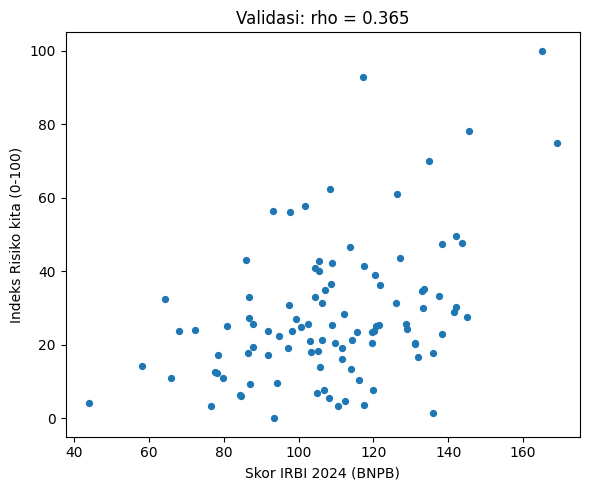

In [18]:
def rho_irbi(x):
    r, p = spearmanr(x, hasil["irbi_skor"])
    return round(r, 3), round(p, 4)

tabel = pd.DataFrame({k: rho_irbi(hasil[k]) for k in ["indeks_risiko", "skor_bahaya", "skor_gempa", "skor_karhutla",
                                                       "skor_lingkungan", "skor_paparan", "skor_kapasitas"]},
                     index=["rho_spearman", "p_value"]).T
print(tabel)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(hasil["irbi_skor"], hasil["indeks_risiko"], s=18)
ax.set_xlabel("Skor IRBI 2024 (BNPB)"); ax.set_ylabel("Indeks Risiko kita (0-100)")
ax.set_title(f"Validasi: rho = {rho_irbi(hasil['indeks_risiko'])[0]}")
plt.tight_layout(); plt.show()

In [19]:
final = pd.concat([fe, mm, zs, idx], axis=1)
final.to_csv(OUT / "tahap3_features.csv", index=False)
print("tersimpan:", OUT / "tahap3_features.csv", "| bentuk:", final.shape)

tersimpan: data/interim/tahap3_features.csv | bentuk: (100, 94)


## Catatan untuk laporan
1. **Reshaping**: melt karhutla wide ke long, lalu grouping per tahun dan per provinsi; fitur tren dihitung dari kemiringan garis 2018-2025.
2. **Transformasi log** untuk fitur miring (sebutkan daftar yang di-log dan skewness sebelum/sesudah).
3. **Dua jenis scaling dan alasannya**: Min-Max untuk indeks, Z-score untuk clustering.
4. **Spearman, bukan Pearson**, karena data miring dan outlier dipertahankan.
5. **Ambang redundansi 0,85** dan aturan fitur wajib; sertakan tabel keputusan seleksi.
6. **Bobot (0,5/0,3/0,2) dan lantai kapasitas 0,1 adalah asumsi awal**; nilainya diuji di analisis sensitivitas.
7. **Validasi IRBI**: laporkan rho dan p-value, bahas perbedaannya jujur. Jangan klaim "terbukti akurat".